# **IMPORT LIBRARY**

In [311]:
# Pengolahan Data
import pandas as pd
import numpy as np

In [312]:
# Preprocessing Teks (NLP)
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [313]:
# Analisis Sentimen
from textblob import TextBlob

In [314]:
# Visualisasi Data
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns

In [315]:
# Analisis Statistik
from scipy.stats import gaussian_kde

| Library                                                   | Fungsi Umum                                                              | Digunakan untuk apa di notebook ini                                                                    |
| --------------------------------------------------------- | ------------------------------------------------------------------------ | ------------------------------------------------------------------------------------------------------ |
| **pandas**                       | Mengolah dan menganalisis data berbentuk tabel (DataFrame).              | Membaca dataset CSV, membersihkan data, memilih kolom, dan melakukan analisis.                         |
| **numpy**                         | Operasi numerik dan array.                                               | Membantu perhitungan statistik dan manipulasi data numerik.                                            |
| **re**                                                    | Regular Expression (pencarian pola teks).                                | Membersihkan teks, misalnya menghapus karakter tertentu, URL, angka, atau pola lainnya pada review.    |
| **string**                                                | Menyediakan kumpulan karakter seperti tanda baca (`string.punctuation`). | Menghapus tanda baca saat preprocessing teks.                                                          |
| **nltk**                                                  | Natural Language Toolkit untuk pemrosesan bahasa alami (NLP).            | Digunakan sebagai dasar berbagai proses NLP.                                                           |
| **nltk.corpus.stopwords**                                 | Menyediakan daftar stopword (kata umum yang kurang bermakna).            | Menghapus kata seperti *the, is, and*, dll. dari review.                                               |
| **nltk.stem.WordNetLemmatizer**                           | Mengubah kata menjadi bentuk dasarnya (lemmatization).                   | Contoh: *running* → *run*, *cars* → *car*.                                                             |
| **TextBlob**                                              | Analisis teks dan sentiment analysis.                                    | Menghitung polaritas sentimen review sehingga dapat dikategorikan positif, negatif, atau netral.       |
| **matplotlib.pyplot**  | Membuat berbagai jenis grafik.                                           | Menampilkan visualisasi seperti histogram, bar chart, KDE plot, dan grafik lainnya.                    |
| **wordcloud.WordCloud**                                   | Membuat Word Cloud dari kumpulan teks.                                   | Menampilkan kata-kata yang paling sering muncul pada review.                                           |
| **seaborn**                      | Visualisasi data statistik yang lebih menarik daripada matplotlib.       | Membuat KDE Plot, distribusi data, heatmap, dan visualisasi statistik lainnya.                         |
| **scipy.stats.gaussian_kde**                              | Menghitung Kernel Density Estimation (KDE).                              | Digunakan untuk memperkirakan distribusi data secara halus, misalnya pada bivariate distribution plot. |


.

# **PREPROCESSING**

### 1. Load Dataset



In [316]:
df = pd.read_excel('raw_cathay_pacific_reviews.xlsx')
df.head()

,Review ID,Title,Reviewer Name,Reviewer Country,Date Published,Overall Rating,Trip Verified,Aircraft,Traveller Type,Seat Class,...,Date Flown,Review,Seat Comfort,Cabin Staff Service,Food & Beverages,Inflight Entertainment,Ground Service,Wifi & Connectivity,Value for Money,Recommended
0,1780466844-1,Cathay Pacific has nailed it,Graham Henrickson,Australia,27th May 2026,10,Trip Verified,Boeing 777-300ER,Solo Leisure,Business Class,...,May 2026,"The business class Aria Suite, I chose 23A for...",5.0,5.0,5.0,5.0,5.0,NaN,5,Yes
1,1780466844-2,excellent in all aspects,B Crockford,United Kingdom,9th May 2026,10,Trip Verified,Boeing 777,Solo Leisure,Business Class,...,April 2026,Consistent with the inbound flight and excelle...,5.0,5.0,5.0,5.0,5.0,NaN,5,Yes
2,1780466844-3,Aria suite is top notch,B Crockford,United Kingdom,9th May 2026,10,Trip Verified,Boeing 777,Solo Leisure,Business Class,...,April 2026,Exceptional in all respects. Superb service ri...,5.0,5.0,5.0,5.0,5.0,1.0,5,Yes
3,1780466844-4,staff service was excellent,J Hasevan,Canada,29th April 2026,9,Trip Verified,A350,Family Leisure,Economy Class,...,April 2026,The flight and travel was smooth. The plane wa...,4.0,4.0,3.0,5.0,4.0,4.0,5,Yes
4,1780466844-5,No option for a cash refund,Salam Abdul,Canada,22nd April 2026,1,Trip Verified,A330-300 / A350-1000,Family Leisure,Economy Class,...,January 2026,I recently traveled with Cathay Pacific from H...,3.0,3.0,3.0,3.0,1.0,3.0,1,No


### 2. Seleksi Kolom

In [317]:
# Mengambil 4 kolom yang ingin digunakan dalam analisis
df.columns = df.columns.str.strip()

df = df[
    [
        'Title',            # Judul singkat review pelanggan.
        'Review',           # Isi lengkap ulasan pelanggan yang akan dianalisis menggunakan NLP.
        'Overall Rating',   # Nilai rating yang diberikan pelanggan (misalnya 1–10).
        'Recommended'       # Apakah pelanggan merekomendasikan maskapai (Yes/No).
    ]
]

df.head()

,Title,Review,Overall Rating,Recommended
0,Cathay Pacific has nailed it,"The business class Aria Suite, I chose 23A for...",10,Yes
1,excellent in all aspects,Consistent with the inbound flight and excelle...,10,Yes
2,Aria suite is top notch,Exceptional in all respects. Superb service ri...,10,Yes
3,staff service was excellent,The flight and travel was smooth. The plane wa...,9,Yes
4,No option for a cash refund,I recently traveled with Cathay Pacific from H...,1,No


### 3. Data Cleaning

In [318]:
# Menghapus data duplikat agar hasil analisis tidak bias
df = df.drop_duplicates()

# Menghapus data kosong (NaN)
df = df.dropna(
    subset=[
        'Title',
        'Review',
        'Overall Rating',
        'Recommended'
    ]
)

# Reset Index agar terurut dan rapi
df = df.reset_index(drop=True)

# Mengecek jumlah baris (row) & kolom (columns)
print(df.shape)

(1500, 4)


In [319]:
# Mengambil seluruh stopword bahasa Inggris dari NLTK
stop_words = set(stopwords.words('english'))
# Membuat objek yang nanti dipakai untuk mengubah kata menjadi bentuk dasar
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Mengubah semua huruf menjadi kecil.
    text = str(text).lower()

    # Menghapus URL
    text = re.sub(r'http\S+|www\S+', '', text)

    # Menghapus Angka
    text = re.sub(r'\d+', '', text)

    # Menghapus Tanda Baca
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Menghapus Spasi Berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenization = Mengubah kalimat menjadi daftar kata.
    tokens = text.split()

    # Stopword Removal (hapus kata tidak penting) + Lemmatization (mengubah kata/kalimat menjadi bentuk dasar)
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    # Menggabungkan kembali kata menjadi kalimat
    return " ".join(tokens)

In [320]:
# Membersihkan seluruh dataset pada kolom Title & Review
df['title_clean'] = df['Title'].apply(clean_text)
df['review_clean'] = df['Review'].apply(clean_text)

### 4. Membuat Sentimen

In [321]:
# Membuat label sentimen berdasarkan Overall Rating (kolom rating)
def create_sentiment(rating):
    if rating <= 4:
        return 0      # Negatif
    elif rating <= 6:
        return 1      # Netral
    else:
        return 2      # Positif

# Membuat kolom baru bernama "sentiment" dengan mengambil seluruh nilai rating
df['sentiment'] = df['Overall Rating'].apply(
    create_sentiment
)

### 5. Encode Recommendation

In [322]:
# Mengubah "yes/no" menjadi angka "1/0" karena komputer lebih mudah mengolah angka daripada teks

df['recommended_binary'] = (
    df['Recommended'] # ambil semua dari kolom recommended
      .astype(str)    # ubah jd string
      .str.lower()    # ubah jd lowercase
      .map({          # encoding
          'yes':1,
          'no':0
      })
)

### 6. Sentiment Polarity

In [323]:
# Mengubah review menjadi nilai sentimen numerik
def get_polarity(text):
    return TextBlob(text).sentiment.polarity # Mengubah review menjadi objek TextBlob

# Membuat kolom baru "polarity" yg engambil seluruh isi review_clean, kemudian untuk setiap review menjalankan fungsi get_polarity().
df['polarity'] = df['review_clean'].apply(
    get_polarity
)

**Perbedaan sentiment & polarity**

| Kolom         | Sumber         | Nilai        | Fungsi                                                      |
| ------------- | -------------- | ------------ | ----------------------------------------------------------- |
| **sentiment** | Overall Rating | 0, 1, 2      | Label kategori berdasarkan rating pelanggan (ground truth). |
| **polarity**  | TextBlob       | -1 sampai +1 | Skor hasil analisis otomatis terhadap isi review.           |

.

Jadi, sentiment bukan hasil TextBlob, melainkan hasil pengelompokan dari Overall Rating. Sedangkan polarity adalah hasil analisis TextBlob terhadap teks review yang sudah dipreprocessing.

.

# **PENYUSUNAN & PENYIMPANAN DATASET HASIL PREPROCESSING**

### Membuat Review_Titles_Data

In [324]:
review_titles_data = df[
    [
        'Title',
        'Review',
        'title_clean',
        'review_clean',
        'polarity'
    ]
]

review_titles_data.to_excel(
    'review_titles_data.xlsx',
    index=False
)

### Membuat Annotated_Sentiment_Dataset

In [325]:
annotated_sentiment_dataset = pd.DataFrame({

    'review': df['Review'],

    'title': df['Title'],

    'rating': df['Overall Rating'],

    'recommended':
        df['recommended_binary'],

    'sentiment':
        df['sentiment']
})

annotated_sentiment_dataset.to_excel(
    'annotated_sentiment_dataset.xlsx',
    index=False
)

| File                                        | Isi                                           | Tujuan                                                                                                    |
| ------------------------------------------- | --------------------------------------------- | --------------------------------------------------------------------------------------------------------- |
| **review_titles_data.csv**                  | Review asli, review bersih, dan polarity      | Membandingkan hasil preprocessing dan analisis sentimen TextBlob.                                         |
| **annotated_sentiment_dataset.csv**         | Review, title, rating, recommended, sentiment | Dataset berlabel (annotated) yang siap digunakan untuk analisis atau pengembangan model machine learning. |

.


# **VISUALISASI DATA**

# **Figure 1 - Word Cloud**

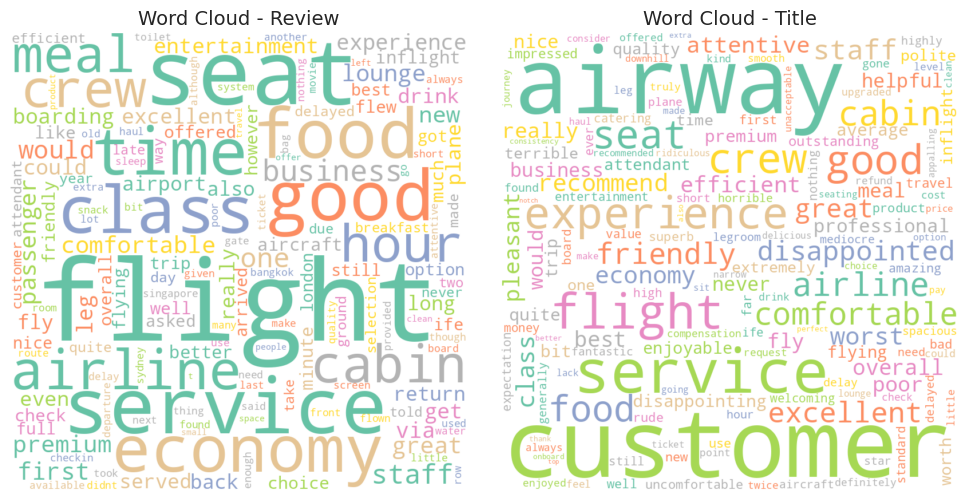

In [326]:
# Load dataset
review_titles_data = pd.read_excel(
    "review_titles_data.xlsx"
)

# Review text
all_review_text = " ".join(
    review_titles_data["review_clean"]
    .fillna("")
    .astype(str)
)

# Title text
all_title_text = " ".join(
    review_titles_data["title_clean"]
    .fillna("")
    .astype(str)
)

# Stopwords tambahan
extra_stopwords = {
    "cathay",
    "pacific",
    "hong",
    "kong",
    "hongkong",
    "hk",
    "hkg",
    "verified",
    "review",
    "cx",
    "u"
}

wc_review = WordCloud(
    width=800,
    height=800,
    background_color="white",
    stopwords=extra_stopwords,
    max_words=150,
    colormap="Set2",
    collocations=False,
    random_state=42
).generate(all_review_text)

wc_title = WordCloud(
    width=800,
    height=800,
    background_color="white",
    stopwords=extra_stopwords,
    max_words=150,
    colormap="Set2",
    collocations=False,
    random_state=42
).generate(all_title_text)

# ==========================================================
# TAMPILKAN BERDAMPINGAN
# ==========================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 5)
)

# Review
axes[0].imshow(
    wc_review,
    interpolation="bilinear"
)
axes[0].axis("off")
axes[0].set_title(
    "Word Cloud - Review",
    fontsize=14
)

# Title
axes[1].imshow(
    wc_title,
    interpolation="bilinear"
)
axes[1].axis("off")
axes[1].set_title(
    "Word Cloud - Title",
    fontsize=14
)

plt.tight_layout()

plt.savefig("figure1_wordcloud_review_title.png", dpi=300, bbox_inches="tight")

plt.show()

Word Cloud dibentuk dari seluruh teks ulasan Cathay Pacific setelah melalui tahap preprocessing. Ukuran kata menunjukkan frekuensi kemunculan dalam dataset, sehingga semakin besar ukuran kata maka semakin sering kata tersebut muncul pada ulasan.

* Flight (flight) menjadi topik yang paling sering dibahas dalam ulasan pelanggan.
* Pelanggan banyak menyoroti layanan (service), awak kabin (crew), dan kenyamanan kursi (seat).
* Makanan (food, meal) dan fasilitas penerbangan juga sering menjadi perhatian pelanggan.
* Terdapat pembahasan mengenai pengalaman pada kelas Business (business class) dan Economy (economy class).
* Fokus utama ulasan berkaitan dengan kualitas layanan (service quality) dan pengalaman perjalanan (flight experience).

# **Figure 2 - Character Distribution Accross Reviews and Titles**

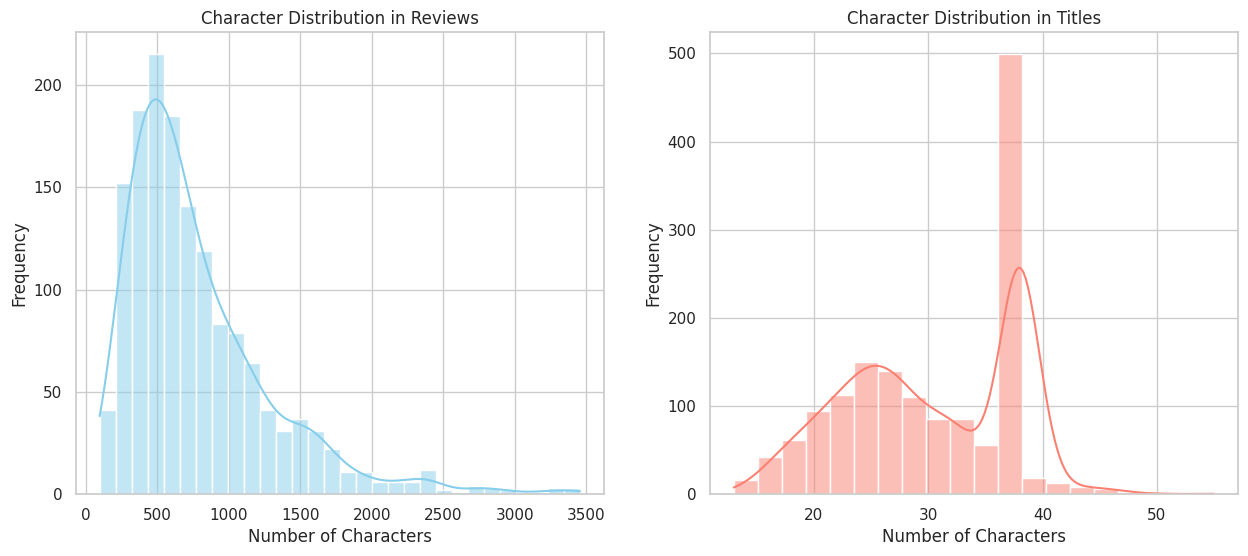

In [327]:
# Set tema visualisasi agar rapi
sns.set_theme(style="whitegrid")

df = pd.read_excel('review_titles_data.xlsx')

# Menghitung jumlah karakter dan kata
df['review_char_count'] = df['Review'].fillna('').apply(len)
df['title_char_count'] = df['Title'].fillna('').apply(len)
df['review_word_count'] = df['Review'].fillna('').apply(lambda x: len(str(x).split()))
df['title_word_count'] = df['Title'].fillna('').apply(lambda x: len(str(x).split()))

# Membuat bidang grafik berdampingan (1 baris, 2 kolom)
fig2, axes2 = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Distribusi Karakter pada Isi Ulasan (Reviews)
sns.histplot(df['review_char_count'], bins=30, kde=True, color='skyblue', ax=axes2[0])
axes2[0].set_title('Character Distribution in Reviews', fontsize=12)
axes2[0].set_xlabel('Number of Characters')
axes2[0].set_ylabel('Frequency')

# Subplot 2: Distribusi Karakter pada Judul Ulasan (Titles)
sns.histplot(df['title_char_count'], bins=20, kde=True, color='salmon', ax=axes2[1])
axes2[1].set_title('Character Distribution in Titles', fontsize=12)
axes2[1].set_xlabel('Number of Characters')
axes2[1].set_ylabel('Frequency')

# Menyimpan file gambar
plt.savefig('figure2_character_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

Visualisasi pada Figure 2 menunjukkan sebaran jumlah karakter secara terpisah
antara isi ulasan (Reviews) dan judul ulasan (Titles).

* Character Distribution in Reviews (Sisi Kiri - Biru Muda):
  - Bentuk Distribusi: Grafik menunjukkan pola distribusi yang condong ke kanan
    (Right-Skewed / Positively Skewed Distribution). Puncak frekuensi tertinggi
    (mode) berada pada rentang 400 hingga 600 karakter. Setelah melewati puncak
    tersebut, frekuensi menurun secara bertahap hingga di atas 3000 karakter.
  - Interpretasi Analisis: Mayoritas penumpang Cathay Pacific cenderung menulis
    umpan balik dengan panjang teks yang ringkas hingga sedang (300-800 karakter).
    Namun, adanya ekor grafik yang memanjang ke sisi kanan (long-tail) menandakan
    adanya sebagian kecil pengguna yang menulis teks sangat panjang (2000-3500
    karakter). Teks yang sangat panjang ini biasanya mengindikasikan ulasan berupa
    kronologi komplain yang mendetail atau laporan perjalanan menyeluruh.

* Character Distribution in Titles (Sisi Kanan - Merah Muda):
  - Bentuk Distribusi: Grafik sebaran karakter pada judul menunjukkan bentuk yang
    unik dengan lonjakan frekuensi ekstrem yang sangat tinggi (spike) pada rentang
    36 hingga 38 karakter, di mana frekuensinya mendekati angka 500. Di luar
    lonjakan tersebut, sebaran data membentuk kurva normal landai pada rentang
    15 hingga 35 karakter.
  - Interpretasi Analisis: Lonjakan tajam di area 36-38 karakter ini mengindikasikan
    adanya kecenderungan standarisasi, pembatasan sistematis (misalnya batas karakter
    input judul ulasan dari platform sumber data), atau penggunaan frasa templat
    yang berulang oleh banyak penumpang saat menuliskan judul ulasan.

# **Figure 3 - Word Distribution Across Reviews and Titles**

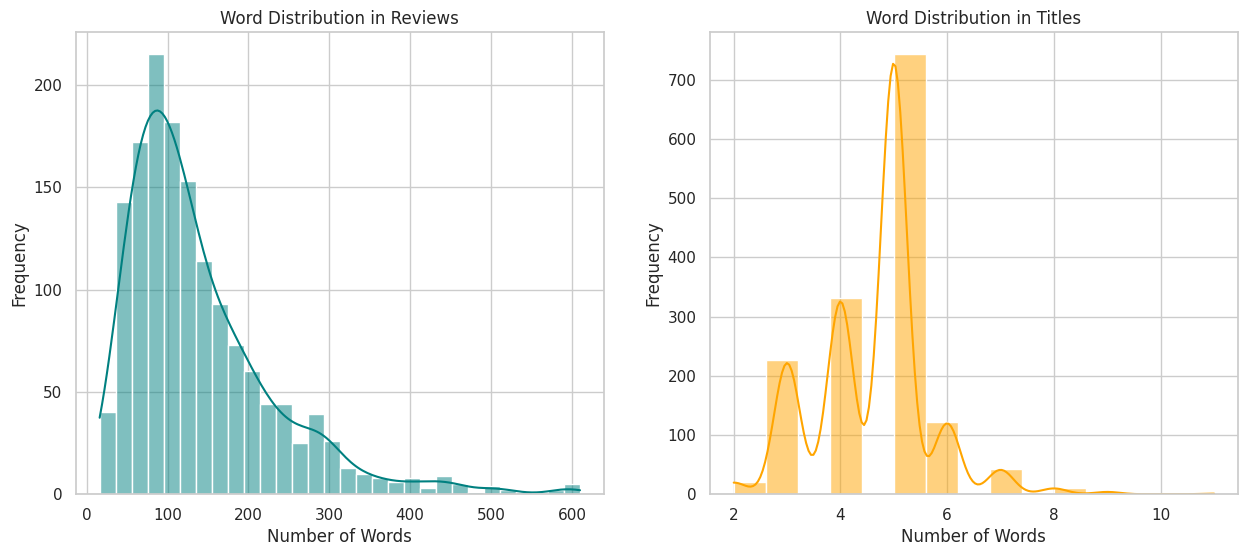

In [328]:
# Membuat bidang grafik berdampingan (1 baris, 2 kolom)
fig3, axes3 = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Distribusi Kata pada Isi Ulasan (Reviews)
sns.histplot(df['review_word_count'], bins=30, kde=True, color='teal', ax=axes3[0])
axes3[0].set_title('Word Distribution in Reviews', fontsize=12)
axes3[0].set_xlabel('Number of Words')
axes3[0].set_ylabel('Frequency')

# Subplot 2: Distribusi Kata pada Judul Ulasan (Titles)
sns.histplot(df['title_word_count'], bins=15, kde=True, color='orange', ax=axes3[1])
axes3[1].set_title('Word Distribution in Titles', fontsize=12)
axes3[1].set_xlabel('Number of Words')
axes3[1].set_ylabel('Frequency')

# Menyimpan file gambar
plt.savefig('figure3_word_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

Visualisasi pada Figure 3 memaparkan sebaran jumlah kata (Word Distribution) untuk
mengonfirmasi karakteristik struktural dari dataset teks yang dianalisis.

* Word Distribution in Reviews (Sisi Kiri - Hijau Toska):
  - Bentuk Distribusi: Pola grafik ini sangat selaras dengan grafik distribusi
    karakter ulasan pada Figure 2, yaitu membentuk kurva Right-Skewed. Konsentrasi
    data terbesar berada pada rentang 70 hingga 110 kata per ulasan. Frekuensi
    tertinggi tercatat di atas nilai 200 untuk ulasan dengan panjang sekitar 90 kata.
  - Interpretasi Analisis: Keselarasan antara distribusi kata dan karakter menunjukkan
    adanya korelasi linear yang kuat. Rentang 70-110 kata dianggap sebagai batas ideal
    bagi penumpang untuk menyampaikan opini mereka secara padat, jelas, dan mencakup
    informasi inti penerbangan (seperti kenyamanan, layanan kru, atau ketepatan waktu).

* Word Distribution in Titles (Sisi Kanan - Jingga):
  - Bentuk Distribusi: Berbeda dengan visualisasi kata pada isi ulasan, distribusi
    kata pada judul memiliki sifat multimodal diskret. Lonjakan frekuensi terbesar
    secara masif terjadi tepat pada angka 5 kata, dengan frekuensi melampaui 700 data.
    Terdapat pula sub-puncak pada angka 4 kata dan 3 kata. Judul ulasan hampir tidak
    ada yang melebihi 8 kata.
  - Interpretasi Analisis: Penumpang sangat menyukai judul yang singkat, padat, dan
    bertindak sebagai kesimpulan utama (punchline). Judul yang terdiri atas 4 sampai
    5 kata merupakan format penulisan paling populer. Informasi ini sangat berguna
    untuk proses Feature Engineering ke depan, di mana batas atas token (padding length)
    untuk judul cukup diset pada nilai maksimum 10-12 kata saja.

Analisis distribusi pada Figure 2 dan Figure 3 ini merepresentasikan salah satu karakteristik utama Big Data, yaitu Variety (Keberagaman) dan Veracity (Kebenaran/Kualitas Data):
1. Variety: Teks ulasan bersifat tidak terstruktur (unstructured data) dengan panjang
   yang sangat bervariasi. Pola Right-Skewed membuktikan bahwa sifat alami dari data
   buatan manusia (human-generated data) tidak menyebar secara simetris sempurna.
2. Veracity: Deteksi anomali seperti lonjakan karakter pada rentang 36-38 karakter
   memberikan informasi penting bagi tim data untuk memahami batasan sistem platform,
   sehingga membantu proses pembersihan data lanjutan (Data Cleaning) agar hasil
   Sentiment Analysis tidak terdistorsi oleh judul templat yang seragam.

# **Figure 4 - Rating Distribution Accross Reviews**

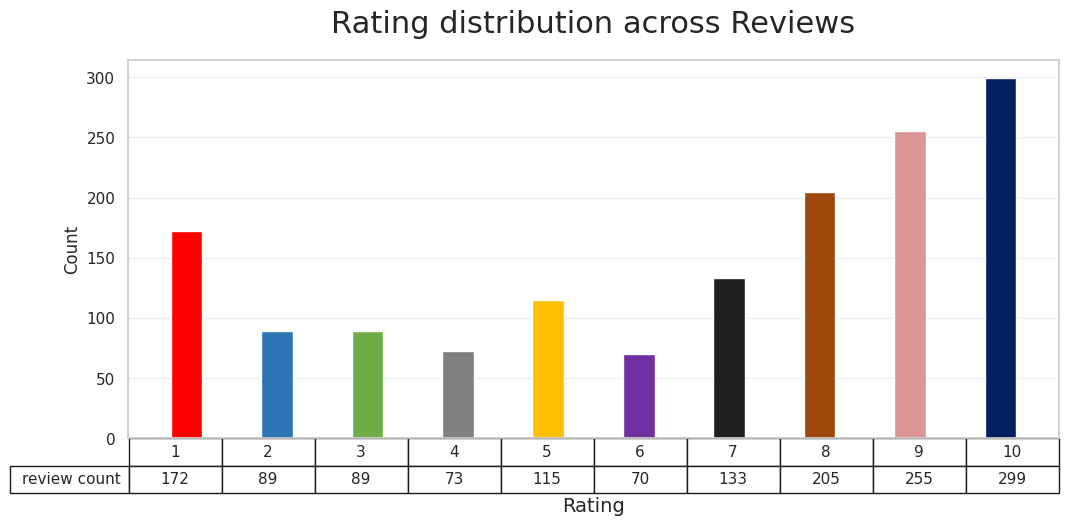

In [329]:
df = pd.read_excel('annotated_sentiment_dataset.xlsx')

# Customer Ratings Across Reviews
# 1. Menghitung distribusi rating
rating_counts = df['rating'].value_counts().sort_index()

# 2. Inisialisasi plot grafik
fig, ax = plt.subplots(figsize=(12, 6))
colors = [
    'red',
    '#2E75B6',
    '#70AD47',
    'gray',
    '#FFC000',
    '#7030A0',
    '#1F1F1F',
    '#9E480E',
    '#D99694',
    '#002060'
]

# 3. Plot grafik batang (Bar Chart)
ax.bar(
    rating_counts.index,
    rating_counts.values,
    color=colors,
    width=0.35
)

# 4. Konfigurasi judul dan sumbu Y
ax.set_title('Rating distribution across Reviews', fontsize=22, pad=20)
ax.set_ylabel('Count', fontsize=12)
ax.grid(axis='y', alpha=0.3)


ax.set_xticks([])

# 5. Membuat tabel di bawah grafik
table = ax.table(
    cellText=[rating_counts.values],
    rowLabels=['review count'],
    colLabels=rating_counts.index,
    loc='bottom',
    cellLoc='center'
)

# 6. Pengaturan ukuran font dan ketebalan baris tabel
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.0)

ax.text(0.5, -0.18, 'Rating', fontsize=14, ha='center', va='center', transform=ax.transAxes)

plt.subplots_adjust(bottom=0.25)
plt.savefig('figure4_rating_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

Mayoritas pengguna memberikan respon yang sangat baik. Hal ini dibuktikan dengan jumlah Rating 10 yang menjadi peraih konsentrasi tertinggi (~300 review), porsi Sentiment Positive yang mendominasi grafik (>59%), serta mayoritas pengguna yang menyatakan Yes (>64%) untuk merekomendasikan maskapai/layanan ini.

# **Figure 5 - Sentiment Class Distribution Across Reviews**

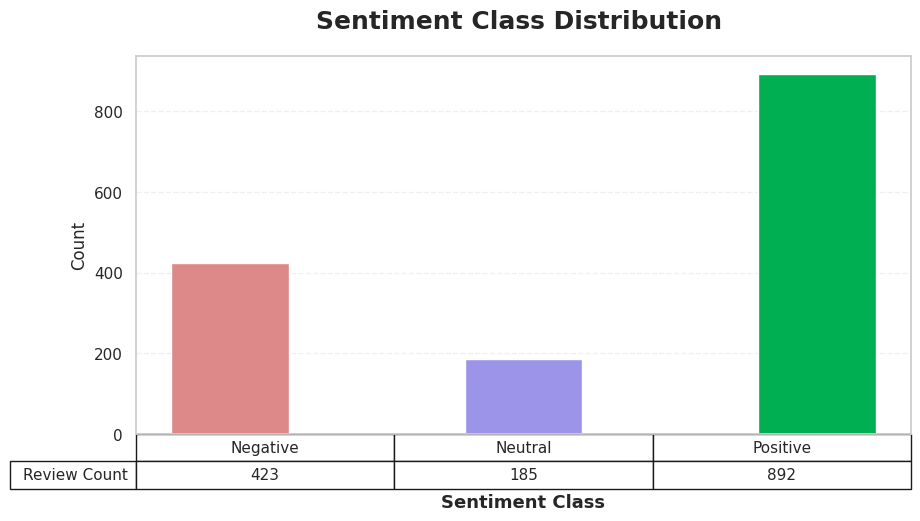

In [330]:
# Sentiment Class Distribution Across Reviews
# 1. Load Data
sentiment_counts = df['sentiment'].map({0: 'Negative', 1: 'Neutral', 2: 'Positive'}).value_counts().reindex(['Negative', 'Neutral', 'Positive'])

# 2. Plot Chart
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#DD8989', '#9C94E8', '#00AF52']

ax.bar(sentiment_counts.index, sentiment_counts.values, color=colors, width=0.4)

# 3. Styling
ax.set_title('Sentiment Class Distribution ', fontsize=18, pad=20, fontweight='bold')
ax.set_ylabel('Count', fontsize=12)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_xticks([])

# 4. Table & X-Label
table = ax.table(
    cellText=[sentiment_counts.values],
    rowLabels=['Review Count'],
    colLabels=sentiment_counts.index,
    loc='bottom',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.0)

ax.text(0.5, -0.18, 'Sentiment Class', fontsize=13, ha='center', va='center', transform=ax.transAxes, fontweight='bold')

plt.subplots_adjust(bottom=0.25)
plt.savefig('figure5_sentiment_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

meskipun tren utama condong ke arah positif, terdapat pola polarisasi yang cukup kuat di sisi ekstrem sebaliknya. Rating 1 menempati posisi kedua tertinggi (~172 review) dan Sentiment Negative mencakup sekitar 28% dari total data. Hal ini menunjukkan adanya kelompok pelanggan yang mengalami masalah atau kekecewaan berat yang kontras dengan mayoritas pelanggan yang puas.

# **Figure 6 - Customer Recommendation Across Reviews**

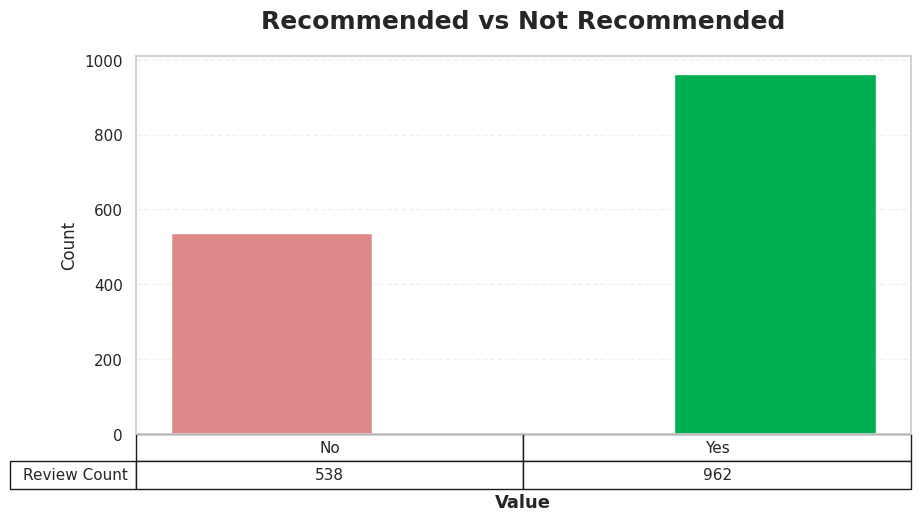

In [331]:
# Customer Recommendation Across Reviews (Figure 8)
# 1. Load Data
recommend_counts = df['recommended'].map({0: 'No', 1: 'Yes'}).value_counts().reindex(['No', 'Yes'])

# 2. Plot Chart
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#DD8989', '#00AF52']

ax.bar(recommend_counts.index, recommend_counts.values, color=colors, width=0.4)

# 3. Styling
ax.set_title('Recommended vs Not Recommended', fontsize=18, pad=20, fontweight='bold')
ax.set_ylabel('Count', fontsize=12)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_xticks([])

# 4. Table & X-Label
table = ax.table(
    cellText=[recommend_counts.values],
    rowLabels=['Review Count'],
    colLabels=recommend_counts.index,
    loc='bottom',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.0)

ax.text(0.5, -0.18, 'Value', fontsize=13, ha='center', va='center', transform=ax.transAxes, fontweight='bold')

plt.subplots_adjust(bottom=0.25)
plt.savefig('figure6_customer_recommendation.png', dpi=300, bbox_inches='tight')
plt.show()

Kelompok pengguna yang merasa biasa saja (Neutral sentiment di angka ~12% dan rating menengah 4–6 yang relatif rendah) sangat sedikit. Pelanggan cenderung memberikan penilaian yang tegas: sangat puas atau sangat kecewa.

# **Figure 7 - Sentiment Polarity Distribution**

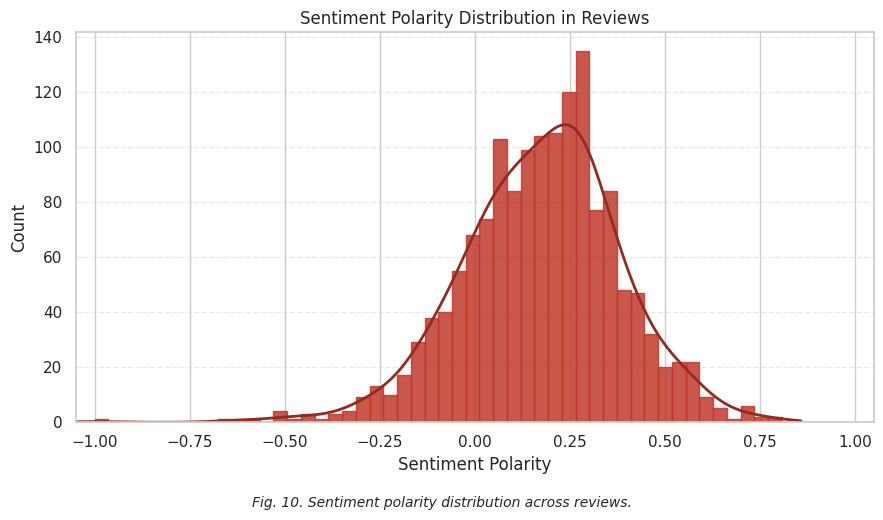

In [332]:
# Load dataset hasil preprocessing
review_titles_data = pd.read_excel(
    "review_titles_data.xlsx"
)

polarities = review_titles_data["polarity"]

fig, ax = plt.subplots(
    figsize=(9,5)
)

n, bins, patches = ax.hist(
    polarities,
    bins=50,
    color="#C0392B",
    edgecolor="#C0392B",
    alpha=0.85
)

# KDE Curve
kde = gaussian_kde(
    polarities,
    bw_method=0.3
)

x_range = np.linspace(
    polarities.min() - 0.05,
    polarities.max() + 0.05,
    300
)

kde_values = (
    kde(x_range)
    * len(polarities)
    * (bins[1] - bins[0])
)

ax.plot(
    x_range,
    kde_values,
    color="#922B21",
    linewidth=2
)

ax.set_xlabel(
    "Sentiment Polarity"
)

ax.set_ylabel(
    "Count"
)

ax.set_title(
    "Sentiment Polarity Distribution in Reviews"
)

ax.set_xlim(-1.05, 1.05)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

fig.text(
    0.5,
    -0.03,
    "Fig. 10. Sentiment polarity distribution across reviews.",
    ha="center",
    fontsize=10,
    style="italic"
)

plt.savefig("figure7_sentiment_polarity.png", dpi=300, bbox_inches="tight")
plt.show()

Figure 7 = Sentiment Polarity Distribution

Menunjukkan kecenderungan sentimen pelanggan terhadap Cathay Pacific (positif, netral, atau negatif).

Tujuannya untuk melihat sebaran nilai sentimen dari seluruh review setelah dihitung menggunakan TextBlob.

| Nilai | Arti           |
| ----- | -------------- |
| -1    | Sangat Negatif |
| 0     | Netral         |
| +1    | Sangat Positif |

Dari grafik terlihat:

- Mayoritas review berada pada rentang 0 sampai 0.4
- Puncak distribusi berada sekitar 0.2–0.3
- Sangat sedikit review yang memiliki polarity negatif (< 0)
- Sebagian review memiliki polarity tinggi (> 0.5)

Artinya: Sebagian besar pelanggan memberikan ulasan dengan sentimen positif terhadap layanan Cathay Pacific

Garis lengkung merupakan Kernel Density Estimation (KDE), yaitu estimasi kepadatan distribusi data yang digunakan untuk memperlihatkan pola sebaran sentimen secara lebih halus dibandingkan histogram.

jelasin cara kerja sentiment.polarity, kok bisa tahu kalimat ini berarti positif, kalimat itu berarti negatif???

nahh, dia pakai *TextBlob().sentiment.polarity*, TextBlob menggunakan kamus sentimen (sentiment lexicon) yang sudah berisi ribuan kata bahasa Inggris beserta skor emosinya.

Saat menerima kalimat, TextBlob:

1. Memecah kalimat menjadi kata-kata.
2. Mencari skor tiap kata di kamus.
3. Menggabungkan seluruh skor.
4. Menghasilkan nilai akhir antara -1 sampai +1

Contoh Positif:

Review: 'The crew was excellent and the seat was comfortable'

Kata yang dianggap positif:
- excellent = +1.0
- comfortable = +0.5

Dengan TextBlob(review).sentiment.polarity, kira akan bernilai --> 0.75

nah jadi si TextBlob itu kek kamus nilai emosi kata2, mulai kata2 positif, ampe kata2 negatif gituuu, lucu juga ada beginian.





# **Figure 8 - The Joint Probability Distribution Plot of Customer Rating & Recommendation Value**

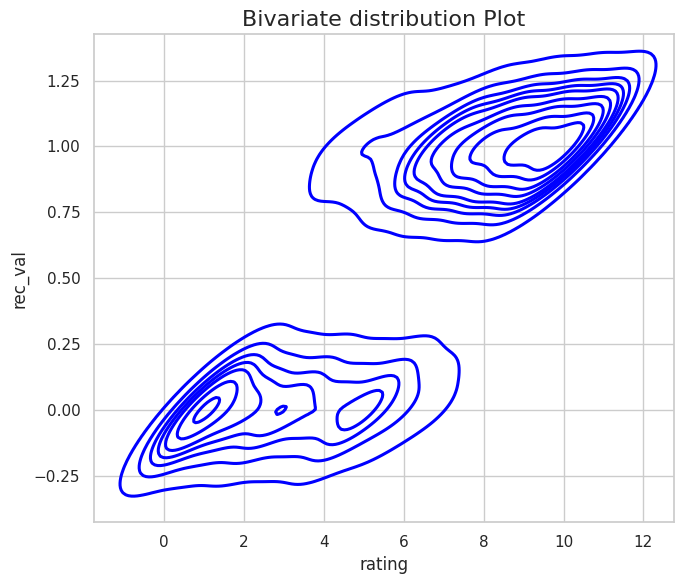

In [333]:
# Membaca dataset
df = pd.read_excel("annotated_sentiment_dataset.xlsx")

# Ukuran gambar
plt.figure(figsize=(7, 6))

# Bivariate Distribution Plot
sns.kdeplot(
    data=df,
    x="rating",
    y="recommended",
    fill=False,
    levels=10,
    color="blue",
    linewidths=2.2
)

# Judul dan label
plt.title("Bivariate distribution Plot", fontsize=16)
plt.xlabel("rating")
plt.ylabel("rec_val")

plt.tight_layout()
plt.savefig('figure8_bivariate_distribution_plot.png', dpi=300, bbox_inches='tight')
plt.show()

Hasil menunjukkan hubungan antara rating pelanggan dan nilai rekomendasi (rec_val). TTerlihat bahwa pelanggan dengan rating tinggi cenderung memberikan rekomendasi, sedangkan pelanggan dengan rating rendah cenderung tidak merekomendasikan layanan. Pola kontur yang membentuk arah diagonal ke atas menunjukkan adanya hubungan positif antara kedua variabel, di mana semakin tinggi rating yang diberikan, semakin besar kemungkinan pelanggan merekomendasikan layanan Cathay Pacific.

# **Figure 9 - The Corelation Heatmap (Customer Rating, Recommendation, Sentiment)**

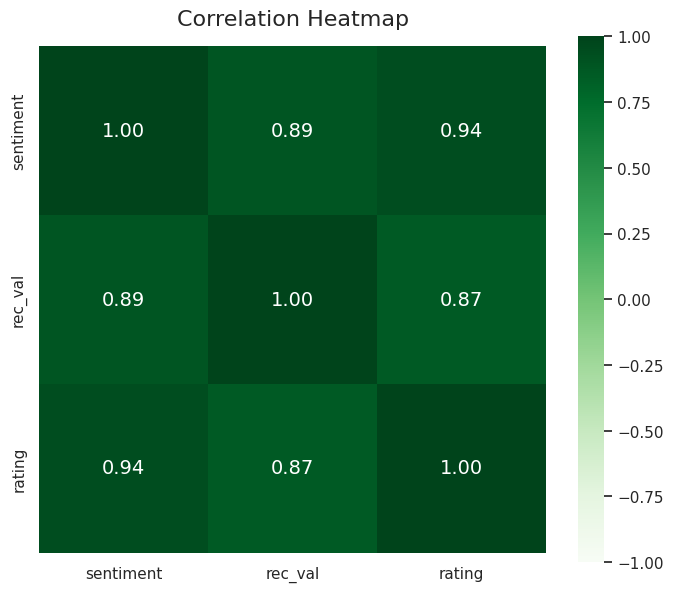

In [334]:
df = pd.read_excel("annotated_sentiment_dataset.xlsx")

df = df.rename(columns={
    "recommended": "rec_val"
})

corr_matrix = df[
    [
        "sentiment",
        "rec_val",
        "rating"
    ]
].corr()

# ==========================================
# PLOT HEATMAP
# ==========================================
plt.figure(figsize=(7,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Greens",
    vmin=-1,
    vmax=1,
    square=True,
    fmt=".2f",
    cbar=True,
    annot_kws={"size":14}
)


plt.title(
    "Correlation Heatmap",
    fontsize=16,
    pad=15
)

plt.tight_layout()
plt.savefig('figure9_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

Hasil menunjukkan korelasi positif yang kuat antara sentiment, rating, dan recommendation value. Nilai korelasi tertinggi terdapat pada sentiment dan rating (0.94), diikuti oleh sentiment dan recommendation (0.89), serta rating dan recommendation (0.87). Hasil ini menunjukkan bahwa pelanggan dengan rating tinggi cenderung memiliki sentimen positif dan lebih bersedia merekomendasikan layanan Cathay Pacific. Secara keseluruhan, ketiga variabel memiliki hubungan yang kuat dalam menggambarkan tingkat kepuasan pelanggan.